In [1]:
import pandas as pd
import numpy as np

# Models
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.metrics import roc_curve, auc
# Preprocessing
from sklearn.preprocessing import MinMaxScaler
from sklearn.decomposition import PCA
from sklearn.impute import KNNImputer

# Evaluation
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

from sklearn.model_selection import train_test_split
import seaborn as sns
import matplotlib.pyplot as plt

In [2]:
df = pd.read_csv("thyroid.csv", header=None)

In [3]:
df.columns = [
    'age','sex','on_thyroxine','query_on_thyroxine',
    'on_antithyroid_medication','sick','pregnant',
    'thyroid_surgery','I131_treatment',
    'query_hypothyroid','query_hyperthyroid',
    'lithium','goitre','tumor','hypopituitary','psych',
    'TSH_measured','TSH',
    'T3_measured','T3',
    'TT4_measured','TT4',
    'T4U_measured','T4U',
    'FTI_measured','FTI',
    'TBG_measured','TBG',
    'referral_source','target'
]

In [4]:
df.replace('?', np.nan, inplace=True)

,age,sex,on_thyroxine,query_on_thyroxine,on_antithyroid_medication,sick,pregnant,thyroid_surgery,I131_treatment,query_hypothyroid,...,TT4_measured,TT4,T4U_measured,T4U,FTI_measured,FTI,TBG_measured,TBG,referral_source,target
0,29,F,f,f,f,f,f,f,f,t,...,f,NaN,f,NaN,f,NaN,f,NaN,other,-[840801013]
1,29,F,f,f,f,f,f,f,f,f,...,t,128,f,NaN,f,NaN,f,NaN,other,-[840801014]
2,41,F,f,f,f,f,f,f,f,f,...,f,NaN,f,NaN,f,NaN,t,11,other,-[840801042]
3,36,F,f,f,f,f,f,f,f,f,...,f,NaN,f,NaN,f,NaN,t,26,other,-[840803046]
4,32,F,f,f,f,f,f,f,f,f,...,f,NaN,f,NaN,f,NaN,t,36,other,S[840803047]
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
9167,56,M,f,f,f,f,f,f,f,f,...,t,64,t,0.83,t,77,f,NaN,SVI,-[870119022]
9168,22,M,f,f,f,f,f,f,f,f,...,t,91,t,0.92,t,99,f,NaN,SVI,-[870119023]
9169,69,M,f,f,f,f,f,f,f,f,...,t,113,t,1.27,t,89,f,NaN,SVI,I[870119025]
9170,47,F,f,f,f,f,f,f,f,f,...,t,75,t,0.85,t,88,f,NaN,other,-[870119027]


In [5]:
df.drop([
    'TBG_measured','TBG',
    'T3_measured','TSH_measured',
    'TT4_measured','T4U_measured',
    'FTI_measured','referral_source'
], axis=1, inplace=True)

In [6]:
df['target'] = df['target'].str.extract('([A-Za-z]+)')
df['target'] = df['target'].fillna('Z')

# Binary
df['target'] = df['target'].apply(lambda x: 0 if x == 'Z' else 1)

In [7]:
binary_cols = [
    'on_thyroxine','query_on_thyroxine','on_antithyroid_medication',
    'sick','pregnant','thyroid_surgery','I131_treatment',
    'query_hypothyroid','query_hyperthyroid',
    'lithium','goitre','tumor','hypopituitary','psych'
]

df[binary_cols] = df[binary_cols].replace({'t':1, 'f':0})
df['sex'] = df['sex'].map({'M': 1, 'F': 2})
df['sex'] = df['sex'].fillna(df['sex'].mode()[0])

In [8]:
imputer = KNNImputer(n_neighbors=3)
num_cols = ['TSH','T3','TT4','T4U','FTI']
df[num_cols] = imputer.fit_transform(df[num_cols])

In [9]:
features = [
    'age','sex','on_thyroxine','query_on_thyroxine',
    'on_antithyroid_medication','sick','pregnant',
    'thyroid_surgery','I131_treatment',
    'query_hypothyroid','query_hyperthyroid',
    'lithium','goitre','tumor','hypopituitary','psych',
    'TSH','T3','T4U','FTI'
]

X = df[features]
y = df['target']

scaler = MinMaxScaler()
scale_cols = ['age','sex','TSH','T3','T4U','FTI']
X[scale_cols] = scaler.fit_transform(X[scale_cols])

In [10]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.33, random_state=42
)

In [11]:
models = {
    "Logistic Regression": LogisticRegression(max_iter=1000),
    "Decision Tree": DecisionTreeClassifier(max_depth=3, random_state=42),
    "Random Forest": RandomForestClassifier(n_estimators=200, max_depth=5, random_state=42),
    "KNN": KNeighborsClassifier(n_neighbors=3),
    "SVM": SVC(kernel='rbf', probability=True)
}

MODELS WITHOUT PCA

In [12]:
results_no_pca = {}

for name, model in models.items():
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)

    results_no_pca[name] = {
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred),
        "Recall": recall_score(y_test, y_pred),
        "F1-score": f1_score(y_test, y_pred),
        "Confusion Matrix": confusion_matrix(y_test, y_pred)
    }

results_no_pca

{'Logistic Regression': {'Accuracy': 0.7558638916418896,
  'Precision': 0.896551724137931,
  'Recall': 0.09653465346534654,
  'F1-score': 0.17430167597765364,
  'Confusion Matrix': array([[2210,    9],
         [ 730,   78]])},
 'Decision Tree': {'Accuracy': 0.8985794516022465,
  'Precision': 0.8408163265306122,
  'Recall': 0.7648514851485149,
  'F1-score': 0.8010369410239793,
  'Confusion Matrix': array([[2102,  117],
         [ 190,  618]])},
 'Random Forest': {'Accuracy': 0.8870168483647175,
  'Precision': 0.8663522012578616,
  'Recall': 0.681930693069307,
  'F1-score': 0.7631578947368421,
  'Confusion Matrix': array([[2134,   85],
         [ 257,  551]])},
 'KNN': {'Accuracy': 0.8490254377271226,
  'Precision': 0.8073555166374781,
  'Recall': 0.5705445544554455,
  'F1-score': 0.668600435097897,
  'Confusion Matrix': array([[2109,  110],
         [ 347,  461]])},
 'SVM': {'Accuracy': 0.7575156921043937,
  'Precision': 0.8363636363636363,
  'Recall': 0.11386138613861387,
  'F1-score'

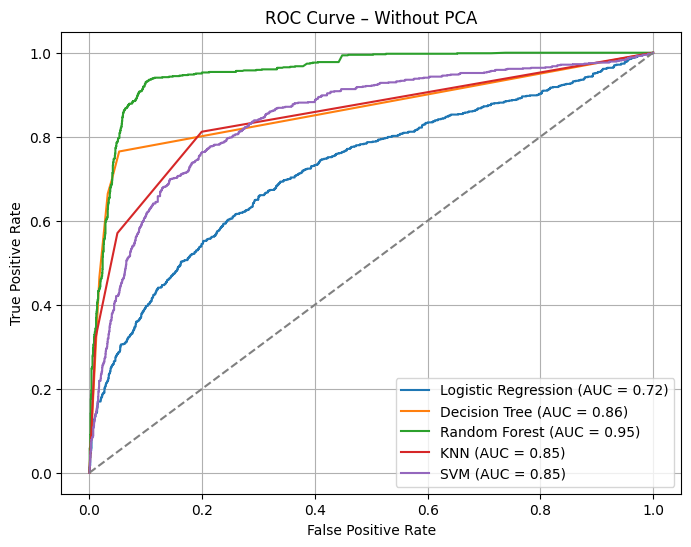

In [13]:
plt.figure(figsize=(8, 6))

for name, model in models.items():
    model.fit(X_train, y_train)

    # For ROC we need probabilities
    if hasattr(model, "predict_proba"):
        y_prob = model.predict_proba(X_test)[:, 1]
    else:
        # For models without predict_proba (fallback)
        y_prob = model.decision_function(X_test)

    fpr, tpr, _ = roc_curve(y_test, y_prob)
    roc_auc = auc(fpr, tpr)

    plt.plot(fpr, tpr, label=f"{name} (AUC = {roc_auc:.2f})")

# Diagonal line (random classifier)
plt.plot([0, 1], [0, 1], linestyle="--", color="gray")

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve – Without PCA")
plt.legend(loc="lower right")
plt.grid()
plt.show()

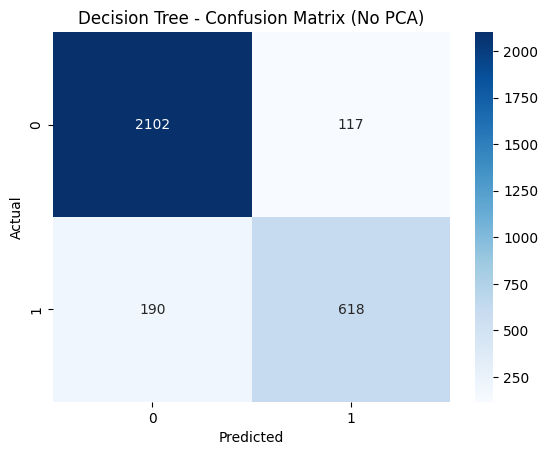

In [14]:
sns.heatmap(
    results_no_pca["Decision Tree"]["Confusion Matrix"],
    annot=True, fmt="d", cmap="Blues"
)
plt.title("Decision Tree - Confusion Matrix (No PCA)")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

MODELS WITH PCA

In [15]:
pca = PCA(n_components=10)
X_pca = pca.fit_transform(X)

X_train_pca, X_test_pca, y_train, y_test = train_test_split(
    X_pca, y, test_size=0.33, random_state=42
)

In [16]:
results_pca = {}

for name, model in models.items():
    model.fit(X_train_pca, y_train)
    y_pred = model.predict(X_test_pca)

    results_pca[name] = {
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred),
        "Recall": recall_score(y_test, y_pred),
        "F1-score": f1_score(y_test, y_pred),
        "Confusion Matrix": confusion_matrix(y_test, y_pred)
    }

results_pca

{'Logistic Regression': {'Accuracy': 0.7333994053518335,
  'Precision': 1.0,
  'Recall': 0.0012376237623762376,
  'F1-score': 0.002472187886279357,
  'Confusion Matrix': array([[2219,    0],
         [ 807,    1]])},
 'Decision Tree': {'Accuracy': 0.7446316484968616,
  'Precision': 0.6804123711340206,
  'Recall': 0.08168316831683169,
  'F1-score': 0.14585635359116023,
  'Confusion Matrix': array([[2188,   31],
         [ 742,   66]])},
 'Random Forest': {'Accuracy': 0.7869177403369673,
  'Precision': 0.7985347985347986,
  'Recall': 0.2698019801980198,
  'F1-score': 0.40333024976873266,
  'Confusion Matrix': array([[2164,   55],
         [ 590,  218]])},
 'KNN': {'Accuracy': 0.8093822266270234,
  'Precision': 0.702276707530648,
  'Recall': 0.4962871287128713,
  'F1-score': 0.5815808556925308,
  'Confusion Matrix': array([[2049,  170],
         [ 407,  401]])},
 'SVM': {'Accuracy': 0.7324083250743311,
  'Precision': 0.42857142857142855,
  'Recall': 0.007425742574257425,
  'F1-score': 0.0

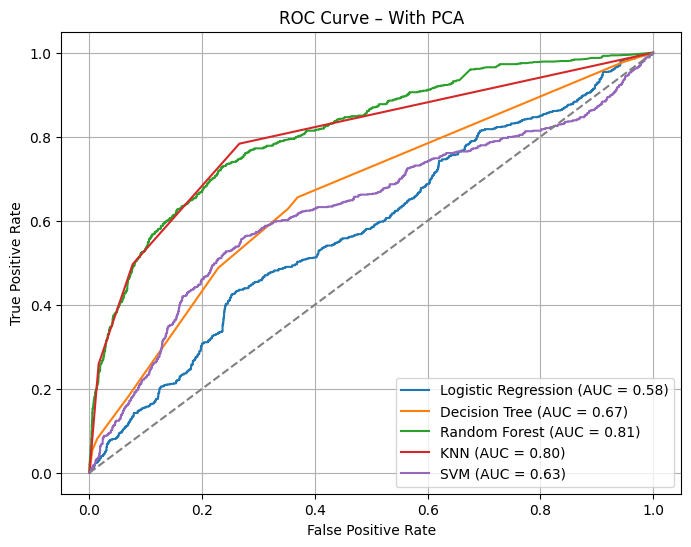

In [17]:
plt.figure(figsize=(8, 6))

for name, model in models.items():
    model.fit(X_train_pca, y_train)

    if hasattr(model, "predict_proba"):
        y_prob = model.predict_proba(X_test_pca)[:, 1]
    else:
        y_prob = model.decision_function(X_test_pca)

    fpr, tpr, _ = roc_curve(y_test, y_prob)
    roc_auc = auc(fpr, tpr)

    plt.plot(fpr, tpr, label=f"{name} (AUC = {roc_auc:.2f})")

plt.plot([0, 1], [0, 1], linestyle="--", color="gray")

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve – With PCA")
plt.legend(loc="lower right")
plt.grid()
plt.show()

In [18]:
comparison = pd.DataFrame({
    "No PCA Accuracy": {k:v["Accuracy"] for k,v in results_no_pca.items()},
    "With PCA Accuracy": {k:v["Accuracy"] for k,v in results_pca.items()}
})

comparison

,No PCA Accuracy,With PCA Accuracy
Logistic Regression,0.755864,0.733399
Decision Tree,0.898579,0.744632
Random Forest,0.887017,0.786918
KNN,0.849025,0.809382
SVM,0.757516,0.732408
